# Next-Hour Bike-Sharing Demand Forecasting and High-Demand Alerts
**ECE 539 · Fall 2026 · Team G02**

## Project Overview
This project aims to help bike-sharing operations planners anticipate
next-hour rental demand and identify high-demand periods. We use the
UCI Bike Sharing Dataset, which contains hourly rental counts,
environmental observations, and calendar information.

## System Pipeline
Our system consists of three connected components:

1. **Environmental Forecasting (NN 1):**
   Uses the previous three hours of temperature, humidity, and wind speed
   to predict these conditions for the next hour.

2. **Rental-Demand Forecasting (NN 2):**
   Combines the predicted environmental conditions, the previous hour’s
   rental count, and target-hour calendar features to predict next-hour
   total rentals.

3. **Demand Analysis and Alerts (Non-neural):**
   Classifies predicted demand as low, medium, or high using thresholds
   derived from training data and flags high-demand hours. It also
   summarizes historical average demand by hour.

**Pipeline:** Historical environment → NN 1 → Predicted environment
→ NN 2 + recent rental count and calendar features → Predicted rentals
→ Demand level and alert

## Main Research Question
Does forecasting next-hour environmental conditions improve rental-demand
prediction compared with using the latest observed conditions?

We compare standard and residual MLPs with an environmental persistence
baseline. We also evaluate how replacing predicted conditions with the
latest observations affects a fixed, trained demand model.

## 1. Environment Setup

In [11]:
%pip install torch numpy pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [12]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    recall_score,
    f1_score,
)

# Set random seeds to improve reproducibility.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select the available device.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")
print(f"Random seed: {SEED}")

PyTorch version: 2.15.0
Device: mps
Random seed: 42



## 2. Data Preparation

We load the hourly bike-sharing data and construct timestamps.
For each target hour, we collect temperature, humidity, and wind speed
from the preceding three hours as inputs. The target is the environmental
conditions recorded at that hour.

Windows with missing hours are excluded to ensure consecutive observations.

In [13]:
from pathlib import Path

# 1. Load and sort the original data.
df = pd.read_csv(Path("../hour.csv"))

df["timestamp"] = (
    pd.to_datetime(df["dteday"])
    + pd.to_timedelta(df["hr"], unit="h")
)

df = df.sort_values("timestamp").reset_index(drop=True)

if df["timestamp"].duplicated().any():
    raise ValueError("Duplicate hourly timestamps found.")

# 2. Create a shared table.
# Each row represents the target hour we want to predict.
env_cols = ["temp", "hum", "windspeed"]
calendar_cols = ["hr", "mnth", "weekday", "workingday", "holiday"]

model_data = df[
    ["timestamp"] + env_cols + calendar_cols + ["cnt"]
].copy()

# 3. Add the preceding three hours of environmental observations.
nn1_input_cols = []

for lag in [3, 2, 1]:
    for col in env_cols:
        lag_col = f"{col}_lag{lag}"
        model_data[lag_col] = df[col].shift(lag)
        nn1_input_cols.append(lag_col)

# 4. Add the previous hour's rental count for NN 2.
model_data["cnt_lag1"] = df["cnt"].shift(1)

# 5. Keep only windows with three consecutive preceding hours.
valid_window = pd.Series(True, index=df.index)

for lag in [1, 2, 3]:
    valid_window &= (
        df["timestamp"] - df["timestamp"].shift(lag)
        == pd.Timedelta(hours=lag)
    )

model_data = (
    model_data.loc[valid_window]
    .dropna()
    .set_index("timestamp")
    .sort_index()
)

# 6. Define the inputs and targets.
nn1_target_cols = env_cols

# These prediction columns will be added AFTER running NN 1.
pred_env_cols = ["pred_temp", "pred_hum", "pred_windspeed"]

# Calendar features are still unencoded at this stage.
nn2_input_cols = pred_env_cols + ["cnt_lag1"] + calendar_cols
nn2_target_col = "cnt"

print(f"Original records: {len(df)}")
print(f"Valid forecasting samples: {len(model_data)}")

display(model_data.head())

Original records: 17379
Valid forecasting samples: 17153


,temp,hum,windspeed,hr,mnth,weekday,workingday,holiday,cnt,temp_lag3,hum_lag3,windspeed_lag3,temp_lag2,hum_lag2,windspeed_lag2,temp_lag1,hum_lag1,windspeed_lag1,cnt_lag1
timestamp,,,,,,,,,,,,,,,,,,,
2011-01-01 03:00:00,0.24,0.75,0.0000,3,1,6,0,0,13,0.24,0.81,0.0,0.22,0.80,0.0000,0.22,0.80,0.0000,32.0
2011-01-01 04:00:00,0.24,0.75,0.0000,4,1,6,0,0,1,0.22,0.80,0.0,0.22,0.80,0.0000,0.24,0.75,0.0000,13.0
2011-01-01 05:00:00,0.24,0.75,0.0896,5,1,6,0,0,1,0.22,0.80,0.0,0.24,0.75,0.0000,0.24,0.75,0.0000,1.0
2011-01-01 06:00:00,0.22,0.80,0.0000,6,1,6,0,0,2,0.24,0.75,0.0,0.24,0.75,0.0000,0.24,0.75,0.0896,1.0
2011-01-01 07:00:00,0.20,0.86,0.0000,7,1,6,0,0,3,0.24,0.75,0.0,0.24,0.75,0.0896,0.22,0.80,0.0000,2.0


##Split data

In [14]:
# Split by target timestamp.
# model_data already uses timestamp as its index.

val_start = pd.Timestamp("2012-05-01")
test_start = pd.Timestamp("2012-09-01")
data_end = pd.Timestamp("2013-01-01")

# Each sample requires three previous hours.
history = pd.Timedelta(hours=3)

train_data = model_data.loc[
    model_data.index < val_start
].copy()

val_data = model_data.loc[
    (model_data.index >= val_start + history)
    & (model_data.index < test_start)
].copy()

test_data = model_data.loc[
    (model_data.index >= test_start + history)
    & (model_data.index < data_end)
].copy()

# Display split sizes and target-time ranges.
for name, split in [
    ("Train", train_data),
    ("Validation", val_data),
    ("Test", test_data),
]:
    print(
        f"{name}: {len(split):,} samples | "
        f"{split.index.min()} → {split.index.max()}"
    )

    # Inputs: nine values from the preceding three hours.
# Targets: three environmental values at the target hour.

X_train = train_data[nn1_input_cols].to_numpy(dtype=np.float32)
y_train = train_data[nn1_target_cols].to_numpy(dtype=np.float32)

X_val = val_data[nn1_input_cols].to_numpy(dtype=np.float32)
y_val = val_data[nn1_target_cols].to_numpy(dtype=np.float32)

X_test = test_data[nn1_input_cols].to_numpy(dtype=np.float32)
y_test = test_data[nn1_target_cols].to_numpy(dtype=np.float32)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: 11,328 samples | 2011-01-01 03:00:00 → 2012-04-30 23:00:00
Validation: 2,949 samples | 2012-05-01 03:00:00 → 2012-08-31 23:00:00
Test: 2,870 samples | 2012-09-01 03:00:00 → 2012-12-31 23:00:00
Train: (11328, 9) (11328, 3)
Validation: (2949, 9) (2949, 3)
Test: (2870, 9) (2870, 3)


## Part 1: Environmental Forecasting

This component predicts next-hour temperature, humidity, and wind speed
using observations from the preceding three consecutive hours.

### Inputs and Targets
- **Input:** Three hourly observations of three environmental variables,
  flattened into a vector of 9 values.
- **Target:** The next hour’s recorded temperature, humidity, and wind speed
  (3 values).

For example, observations at 00:00, 01:00, and 02:00 are used to predict
conditions at 03:00.

### Methods
We will compare three approaches:

1. **Persistence baseline:** Use the latest observed conditions as the
   next-hour prediction.
2. **Standard MLP:** Directly predict the three next-hour environmental values.
3. **Residual MLP:** Predict changes and add them to the latest observations:

   predicted next-hour conditions = latest conditions + predicted changes

### 1. Persistence baseline

The persistence baseline assumes that next-hour environmental conditions
remain unchanged from the latest observations.

- Input: Temperature, humidity, and wind speed from the previous hour.
- Output: The same values, used as next-hour predictions.
- Training: None.

We evaluate validation MAE and RMSE for each variable on the same samples
and CSV scale used for the standard MLP.

In [15]:
# Use the latest observed environmental values.
# Column order matches nn1_target_cols: temp, hum, windspeed.
latest_env_cols = [
    "temp_lag1",
    "hum_lag1",
    "windspeed_lag1",
]

persistence_val_pred = val_data[latest_env_cols].to_numpy(
    dtype=np.float32
)

# Actual next-hour conditions, on the original CSV scale.
val_actual = val_data[nn1_target_cols].to_numpy(
    dtype=np.float32
)

# Evaluate each environmental variable.
metrics = []

for i, variable in enumerate(nn1_target_cols):
    metrics.append({
        "Variable": variable,
        "MAE": mean_absolute_error(
            val_actual[:, i], persistence_val_pred[:, i]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                val_actual[:, i], persistence_val_pred[:, i]
            )
        ),
    })

persistence_val_metrics = pd.DataFrame(
    metrics
).set_index("Variable")

display(persistence_val_metrics)

# Preserve target timestamps.
persistence_val_predictions = pd.DataFrame(
    persistence_val_pred,
    index=val_data.index,
    columns=["pred_temp", "pred_hum", "pred_windspeed"],
)

,MAE,RMSE
Variable,,
temp,0.016656,0.025254
hum,0.041913,0.061645
windspeed,0.062031,0.088153


### 2.Standard MLP

The standard MLP directly predicts next-hour temperature, humidity,
and wind speed from the preceding three hours of observations.

- Input: 9 values (3 hours × 3 environmental variables).
- Hidden layers: 32 and 16 neurons with ReLU activation.
- Output: 3 next-hour environmental values.
- Training: Adam optimizer and mean squared error (MSE).
- Model selection: Early stopping based on validation MSE.

Input and target scaling parameters are fitted on training data only.
Predictions are converted back to the dataset's original scale for
reporting validation MAE and RMSE. The test set remains reserved for
final evaluation.

In [16]:
from copy import deepcopy

# Fit scalers using training data only.
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = x_scaler.transform(X_val).astype(np.float32)

y_train_scaled = y_scaler.fit_transform(y_train).astype(np.float32)
y_val_scaled = y_scaler.transform(y_val).astype(np.float32)

train_dataset = TensorDataset(
    torch.from_numpy(X_train_scaled),
    torch.from_numpy(y_train_scaled),
)

# Reproducible batch shuffling.
generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    generator=generator,
)

X_val_tensor = torch.from_numpy(X_val_scaled).to(device)
y_val_tensor = torch.from_numpy(y_val_scaled).to(device)

In [17]:
class StandardMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(9, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3),
        )

    def forward(self, x):
        return self.network(x)


torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

standard_mlp = StandardMLP().to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    standard_mlp.parameters(),
    lr=1e-3,
)

print(standard_mlp)

StandardMLP(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


In [18]:
max_epochs = 200
patience = 20

best_val_loss = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0

history = {"train": [], "val": []}

for epoch in range(1, max_epochs + 1):
    # Training
    standard_mlp.train()
    total_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = standard_mlp(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * X_batch.size(0)

    train_loss = total_train_loss / len(train_dataset)

    # Validation: no parameter updates
    standard_mlp.eval()

    with torch.no_grad():
        val_predictions = standard_mlp(X_val_tensor)
        val_loss = criterion(val_predictions, y_val_tensor).item()

    if not np.isfinite(train_loss) or not np.isfinite(val_loss):
        raise RuntimeError("Non-finite loss detected. Check inputs and training.")

    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = deepcopy(standard_mlp.state_dict())
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Train MSE: {train_loss:.5f} | "
            f"Validation MSE: {val_loss:.5f}"
        )

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}.")
        break

# Restore the best validation checkpoint.
standard_mlp.load_state_dict(best_state)
standard_mlp.eval()

print(f"Best epoch: {best_epoch}")
print(f"Best validation MSE: {best_val_loss:.5f}")

Epoch   1 | Train MSE: 0.66410 | Validation MSE: 0.26682
Epoch  10 | Train MSE: 0.16280 | Validation MSE: 0.15642
Epoch  20 | Train MSE: 0.15987 | Validation MSE: 0.15570
Epoch  30 | Train MSE: 0.15818 | Validation MSE: 0.15448
Epoch  40 | Train MSE: 0.15695 | Validation MSE: 0.15374
Epoch  50 | Train MSE: 0.15637 | Validation MSE: 0.15439
Epoch  60 | Train MSE: 0.15621 | Validation MSE: 0.15446
Epoch  70 | Train MSE: 0.15619 | Validation MSE: 0.15458
Epoch  80 | Train MSE: 0.15536 | Validation MSE: 0.15387
Early stopping at epoch 81.
Best epoch: 61
Best validation MSE: 0.15265


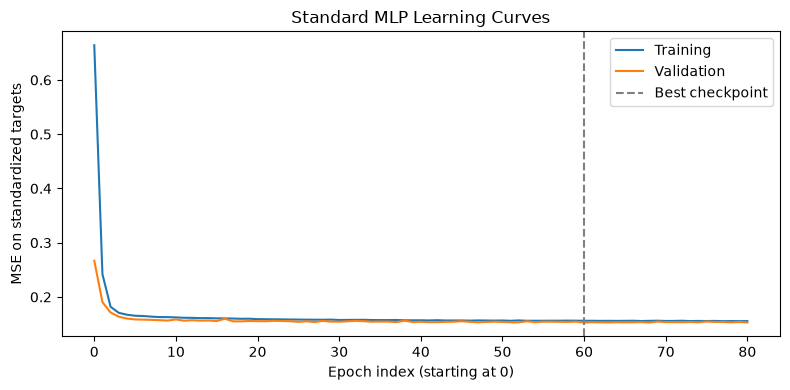

,MAE,RMSE
Variable,,
temp,0.016149,0.022840
hum,0.040328,0.055705
windspeed,0.056766,0.076290


,pred_temp,actual_temp,pred_hum,actual_hum,pred_windspeed,actual_windspeed
timestamp,,,,,,
2012-05-01 03:00:00,0.497559,0.50,0.715242,0.77,0.105261,0.0000
2012-05-01 04:00:00,0.501245,0.52,0.758107,0.72,0.068427,0.0896
2012-05-01 05:00:00,0.525788,0.52,0.714500,0.72,0.090670,0.0896
2012-05-01 06:00:00,0.528313,0.52,0.715260,0.77,0.094450,0.1045
2012-05-01 07:00:00,0.517802,0.50,0.765572,0.94,0.098462,0.2537


In [19]:
# Plot losses on the standardized target scale.
plt.figure(figsize=(8, 4))
plt.plot(history["train"], label="Training")
plt.plot(history["val"], label="Validation")
plt.axvline(
    best_epoch - 1,
    color="gray",
    linestyle="--",
    label="Best checkpoint",
)
plt.xlabel("Epoch index (starting at 0)")
plt.ylabel("MSE on standardized targets")
plt.title("Standard MLP Learning Curves")
plt.legend()
plt.tight_layout()
plt.show()

# Predict and return to the CSV scale.
with torch.no_grad():
    val_pred_scaled = standard_mlp(X_val_tensor).cpu().numpy()

val_pred = y_scaler.inverse_transform(val_pred_scaled)

# Evaluate each variable separately.
metrics = []

for i, variable in enumerate(nn1_target_cols):
    metrics.append({
        "Variable": variable,
        "MAE": mean_absolute_error(y_val[:, i], val_pred[:, i]),
        "RMSE": np.sqrt(
            mean_squared_error(y_val[:, i], val_pred[:, i])
        ),
    })

standard_val_metrics = pd.DataFrame(metrics).set_index("Variable")
display(standard_val_metrics)

# Preserve target timestamps for later alignment.
standard_val_predictions = pd.DataFrame(
    val_pred,
    index=val_data.index,
    columns=["pred_temp", "pred_hum", "pred_windspeed"],
)
# Add actual values, aligned by timestamp.
for variable in nn1_target_cols:
    standard_val_predictions[f"actual_{variable}"] = val_data[variable]

# Place each prediction next to its actual value.
standard_val_predictions = standard_val_predictions[
    [
        "pred_temp", "actual_temp",
        "pred_hum", "actual_hum",
        "pred_windspeed", "actual_windspeed",
    ]
]

display(standard_val_predictions.head())